# 🐍 Introducción a Python Moderno: Fundamentos, Type Hints y POO

Esta guía interactiva unifica los conceptos clave para iniciar en el desarrollo de software profesional utilizando **Python moderno**. A lo largo de este Notebook aprenderás a escribir código limpio, legible y fuertemente tipado utilizando las mejores prácticas de la industria actual.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/secorto/notebooks/blob/main/spanish/poo-python.ipynb)


## Setup de diagramas

Para este notebook estaremos usando plantuml entonces instala la extensión ejecutando las siguientes celdas

In [1]:
!pip install iplantuml

In [2]:
import iplantuml

## 1. El Concepto de Objeto en Python

La programación orientada a objetos (POO) parte del concepto de "objetos" como bloques de construcción esenciales. Un objeto contiene información estructurada (atributos) y funciones capaces de operar sobre ellos (métodos).

A diferencia de otros lenguajes, en Python debemos ser explícitos. En cada método de instancia, es obligatorio recibir la referencia al propio objeto, el cual por convención estricta llamamos `self` (el equivalente a `this` en TypeScript, C++ o Java).


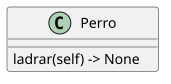

In [3]:
%%plantuml

@startuml
Perro : ladrar(self) -> None
@enduml

In [4]:
class Perro:
    def ladrar(self) -> None:
        print("¡Guau guau!")

# Instanciamos la clase y ejecutamos su método
mi_perro = Perro()
mi_perro.ladrar()

¡Guau guau!


Si omites colocar `self` como primer parámetro de un método de instancia, Python arrojará un error de tipo (`TypeError`) cuando intentes invocarlo, avisando que se le envió un argumento implícito inesperado.

### Métodos Estáticos
Si necesitas agrupar un método utilitario dentro de una clase que no requiera acceder a las propiedades del objeto o la clase, puedes usar el decorador `@staticmethod` para prescindir de `self`.

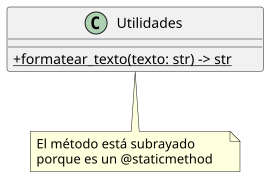

In [5]:
%%plantuml

@startuml
skinparam classAttributeIconSize 0

class Utilidades {
  {static} +formatear_texto(texto: str) -> str
}

note bottom of Utilidades
  El método está subrayado
  porque es un @staticmethod
end note
@enduml


In [6]:
class Utilidades:
    @staticmethod
    def formatear_texto(texto: str) -> str:
        return texto.strip().capitalize()

print(Utilidades.formatear_texto("   hola mundo de python   "))

Hola mundo de python


## 2. Estructuración Moderna de Datos: Type Hints y `@dataclass`

Tradicionalmente, en Python las propiedades de los objetos se definían de forma dinámica dentro de un constructor especial llamado `__init__`. Sin embargo, el ecosistema moderno prefiere el tipado estático opcional (**Type Hints - PEP 484**) para proveer autocompletado robusto y detección de errores previa a la ejecución.

A partir de Python 3.7, contamos con el decorador `@dataclass`. Este enfoque moderno simplifica radicalmente el código repetitivo (*boilerplate*), autogenerando constructores, comparadores y representaciones legibles de forma nativa.


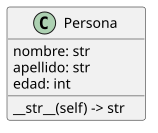

In [7]:
%%plantuml

@startuml
Persona : nombre: str
Persona : apellido: str
Persona : edad: int
Persona : __str__(self) -> str
@enduml

In [8]:
from dataclasses import dataclass

@dataclass
class Persona:
    # Definimos atributos utilizando Type Hints de forma clara y explícita
    nombre: str
    apellido: str
    edad: int

    # El método especial __str__ define qué mostrar al usar print()
    def __str__(self) -> str:
        return f"{self.nombre} {self.apellido} ({self.edad} años)"

# Creación directa gracias al constructor autogenerado por @dataclass
desarrollador = Persona(nombre="Sergio", apellido="Orozco", edad=30)
print(desarrollador)

Sergio Orozco (30 años)


## 3. Sobrecarga de Operadores y Métodos Mágicos

Python expone una serie de métodos especiales delimitados por un doble guion bajo inicial y final (`__`), comúnmente denominados *métodos mágicos* o *dunder methods*. Éstos te permiten modificar el comportamiento intrínseco del lenguaje para tus propios objetos, como definir qué ocurre al sumar o restar dos instancias empleando los operadores tradicionales `+` y `-`.


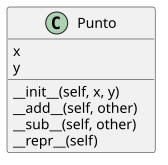

In [9]:
%%plantuml

@startuml
Punto : x
Punto : y

Punto : __init__(self, x, y)
Punto : __add__(self, other)
Punto : __sub__(self, other)
Punto : __repr__(self)
@enduml

In [10]:
from __future__ import annotations
class Punto:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    # Sobrecarga del operador +
    def __add__(self, other: 'Punto') -> Punto:
        return Punto(self.x + other.x, self.y + other.y)

    # Sobrecarga del operador -
    def __sub__(self, other: 'Punto') -> Punto:
        return Punto(self.x - other.x, self.y - other.y)

    # Representación de desarrollo del objeto
    def __repr__(self) -> str:
        return f"Punto({self.x}, {self.y})"

p1 = Punto(5, 12)
p2 = Punto(3, 4)

print("Suma de puntos:", p1 + p2)
print("Resta de puntos:", p1 - p2)

Suma de puntos: Punto(8, 16)
Resta de puntos: Punto(2, 8)


## 4. Herencia, Polimorfismo y Relaciones entre Clases

La herencia permite estructurar especializaciones de código compartiendo lógica común desde un ancestro o clase base. Una clase derivada hereda atributos y métodos, permitiendo extender la funcionalidad o redefinir comportamientos específicos (Polimorfismo).


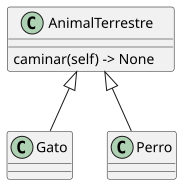

In [11]:
%%plantuml

@startuml
AnimalTerrestre : caminar(self) -> None

AnimalTerrestre <|-- Gato
AnimalTerrestre <|-- Perro
@enduml


In [12]:
class AnimalTerrestre:
    def caminar(self) -> None:
        print("El animal avanza sobre la superficie.")

class Perro(AnimalTerrestre):
    # Hereda el comportamiento de caminar de forma intacta
    pass

class Gato(AnimalTerrestre):
    # Polimorfismo: Sobreescritura del método para especializarlo
    def caminar(self) -> None:
        print("El gato camina con sigilo absoluto 🐾")

print("Comportamiento de Perro:")
p = Perro()
p.caminar()

print("\nComportamiento de Gato:")
g = Gato()
g.caminar()

Comportamiento de Perro:
El animal avanza sobre la superficie.

Comportamiento de Gato:
El gato camina con sigilo absoluto 🐾


### Herencia Múltiple y el Problema del Diamante

Python es uno de los pocos lenguajes de alto nivel que admite herencia múltiple de manera nativa. Cuando se presenta una ambigüedad donde dos clases base comparten un ancestro común y sobreescriben el mismo método (el Problema del Diamante), Python aplica un algoritmo riguroso llamado **MRO (Method Resolution Order)** para decidir qué implementación ejecutar basándose en el orden de declaración.


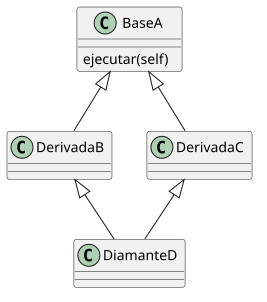

In [13]:
%%plantuml
@startuml
BaseA : ejecutar(self)

BaseA <|-- DerivadaB
BaseA <|-- DerivadaC
DerivadaB <|-- DiamanteD
DerivadaC <|-- DiamanteD
@enduml

In [14]:
class BaseA:
    def ejecutar(self) -> None:
        print("Ejecutando desde BaseA")

class DerivadaB(BaseA):
    def ejecutar(self) -> None:
        print("Ejecutando desde DerivadaB")

class DerivadaC(BaseA):
    def ejecutar(self) -> None:
        print("Ejecutando desde DerivadaC")

# El orden de declaración (DerivadaB primero) dicta la prioridad en el MRO
class DiamanteD(DerivadaB, DerivadaC):
    pass

instancia_d = DiamanteD()
instancia_d.ejecutar()

# Podemos inspeccionar el orden de resolución exacto usando __mro__
print("\nOrden MRO de la clase:", [cls.__name__ for cls in DiamanteD.__mro__])

Ejecutando desde DerivadaB

Orden MRO de la clase: ['DiamanteD', 'DerivadaB', 'DerivadaC', 'BaseA', 'object']


## 5. La Filosofía del Lenguaje: Duck Typing

En lenguajes puramente estáticos, para que dos objetos sean tratados igual en una función deben implementar la misma interfaz o heredar de la misma clase. Python utiliza **Duck Typing**: *"Si camina como un pato, grazna como un pato, entonces lo tratamos como un pato"*.

Si una porción de tu código requiere invocar un método específico (como `.volar()`), cualquier objeto que provea dicho método podrá ser utilizado, sin importar su árbol genealógico.

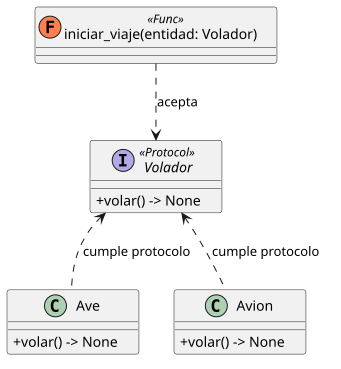

In [15]:
%%plantuml

@startuml
skinparam classAttributeIconSize 0

interface Volador <<Protocol>> {
  +volar() -> None
}

class Ave {
  +volar() -> None
}

class Avion {
  +volar() -> None
}

class "iniciar_viaje(entidad: Volador)" as Funcion <<(F,#FF7F50) Func>> {
}

' Relación de compatibilidad estructural (implementación implícita)
Volador <.. Ave : cumple protocolo
Volador <.. Avion : cumple protocolo

' Dependencia de la función respecto al protocolo
Funcion ..> Volador : acepta
@enduml


In [16]:
from typing import Protocol

# Definimos un Protocolo (interfaz estructural moderna en Python)
class Volador(Protocol):
    def volar(self) -> None: ...

class Ave:
    def volar(self) -> None:
        print("El ave bate sus alas en el cielo.")

class Avion:
    def volar(self) -> None:
        print("El avión enciende sus turbinas de combustible.")

# Esta función acepta cualquier objeto que cumpla con el protocolo Volador
def iniciar_viaje(entidad: Volador) -> None:
    entidad.volar()

# Ambas clases son estructuralmente compatibles sin herencia explícita
iniciar_viaje(Ave())
iniciar_viaje(Avion())

El ave bate sus alas en el cielo.
El avión enciende sus turbinas de combustible.


## Conclusiones y Próximos Pasos

¡Felicitaciones! Has dominado las bases del modelado de software e ingeniería de código en Python Moderno. Escribir aplicaciones estructurando tus datos mediante `dataclasses` y definiendo contratos limpios con `Type Hints` te preparará para interactuar eficientemente con frameworks profesionales como FastAPI, Pydantic o SQLAlchemy.

### Recursos recomendados para expandir tu conocimiento:
- **Documentación Oficial de Type Hints:** [PEP 484](https://peps.python.org/pep-0484/)
- **Patrones de Diseño en Python:** Explora implementaciones avanzadas en [Refactoring Guru](https://refactoring.guru/es/design-patterns/python)
- **Ecosistema de datos:** Curso de desarrollo y modelado interactivo en [DataCamp](https://www.datacamp.com/courses/intro-to-python-for-data-science)